# Forecasting Business and Financial Metrics — Dataset + Data Collection

**Dataset:** Quarterly financial statements of 400 US-listed companies, 2018–2026
**File:** `kvartalni_podaci (2).csv` (same folder as this notebook, or `C:\Users\User\Desktop`)

## 1. Project questions

1. **Revenue:** How will revenue change over the next two quarters?
2. **Financial stability:** Which companies are at risk of weakening financial stability?
3. **Profitability:** Will operating margin improve or decline next quarter?



## 2. Data source and usage rules

| Item | Description |
|---|---|
| Origin | Figures companies report to the US Securities and Exchange Commission (SEC) in 10-Q / 10-K filings, published as XBRL "Company Facts" through SEC EDGAR (`https://data.sec.gov/api/xbrl/companyfacts/CIK##########.json`). Column `cik` is the EDGAR company key and `revenue_concept` holds the original XBRL tag. |
| Type of data | **Public** corporate disclosures. No personal data, no confidential or proprietary records. |
| Usage rules | SEC EDGAR content is public and may be copied and redistributed; automated access must follow the SEC fair-access policy (declared User-Agent, max. 10 requests/second). |
| Unit of observation | One company × one fiscal quarter (primary key: `cik` + `period_end`). |
| Coverage | 400 US-listed companies (S&P 500 snapshot incl. Dow Jones and Nasdaq members), fiscal quarters ending Jan 2018 – Oct 2026. |
| Collected | **9 November 2026** – dataset built from SEC EDGAR Company Facts (filings available up to that date). |
| Files | Raw: `kvartalni_podaci (2).csv` (never modified). Outputs of this notebook: `capstone_output/quarterly_clean.csv` and `capstone_output/data_dictionary.csv` next to the raw file. |

Quarterly values that a company does not report directly (mostly Q4, which only appears in the annual 10-K) were derived as differences of cumulative figures – see column `net_income_method`.

## 3. Setup

In [74]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns   # if missing: run  %pip install seaborn  in a separate cell
from IPython.display import display

# The CSV is looked for next to the notebook first, then at the original location
FILE_NAME = "kvartalni_podaci (2).csv"
candidates = [Path.cwd() / FILE_NAME, Path(r"C:\Users\User\Desktop") / FILE_NAME]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(f"'{FILE_NAME}' not found in: {[str(p.parent) for p in candidates]}")

OUT_DIR = DATA_PATH.parent / "capstone_output"
OUT_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 80, "display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
print("Data file :", DATA_PATH)
print("Output dir:", OUT_DIR)

Data file : c:\Users\User\Desktop\kvartalni_podaci (2).csv
Output dir: c:\Users\User\Desktop\capstone_output


## 4. Open and inspect the raw data

In [75]:
# utf-8-sig removes the byte-order mark at the start of the file
raw = pd.read_csv(DATA_PATH, encoding="utf-8-sig", low_memory=False)
print(f"Rows: {raw.shape[0]:,}   Columns: {raw.shape[1]}")
raw.head()

Rows: 13,966   Columns: 66


,cik,ticker,company,period_start,period_end,calendar_year,calendar_quarter,revenue,cost_of_revenue,gross_profit,operating_income,net_income,pretax_income,income_tax_expense,research_development,selling_general_admin,operating_expenses,interest_expense,eps_basic,eps_diluted,shares_basic,shares_diluted,assets,current_assets,noncurrent_assets,liabilities,current_liabilities,noncurrent_liabilities,equity,equity_including_minority,liabilities_and_equity,cash,cash_restricted,receivables,inventory,ppe_net,goodwill,intangibles_net,accounts_payable,retained_earnings,treasury_stock,short_term_borrowings,long_term_debt_current,long_term_debt_noncurrent,deferred_revenue_current,operating_cash_flow,investing_cash_flow,financing_cash_flow,capex,acquisitions_cash,depreciation_amortization,stock_compensation,dividends_paid,share_repurchases,debt_repayments,debt_issued,income_taxes_paid,interest_paid,dividend_per_share,shares_outstanding,revenue_concept,net_income_method,core_available,balance_identity_difference,balance_identity_status,free_cash_flow
0,320193,AAPL,Apple Inc.,12/31/2017,3/31/2018,2018,1,"61,137,000,000.00","37,715,000,000.00","23,422,000,000.00","15,894,000,000.00","13,822,000,000.00","16,168,000,000.00","2,346,000,000.00","3,378,000,000.00","4,150,000,000.00","7,528,000,000.00","792,000,000.00",2.75,2.73,"5,024,877,000.00","5,068,493,000.00","367,502,000,000.00","130,053,000,000.00",NaN,"240,624,000,000.00","89,320,000,000.00",NaN,"126,878,000,000.00",NaN,"367,502,000,000.00","45,059,000,000.00","45,059,000,000.00","14,324,000,000.00","7,662,000,000.00","35,077,000,000.00",NaN,NaN,"34,311,000,000.00","91,898,000,000.00",NaN,NaN,"8,498,000,000.00","101,362,000,000.00","7,775,000,000.00","15,130,000,000.00","28,710,000,000.00","-26,272,000,000.00","4,195,000,000.00","132,000,000.00","2,739,000,000.00","1,348,000,000.00","3,190,000,000.00","22,756,000,000.00",NaN,0.00,"2,789,000,000.00","733,000,000.00",0.63,"4,943,282,000.00",RevenueFromContractWithCustomerExcludingAssess...,reported,1,0.00,pass,"10,935,000,000.00"
1,320193,AAPL,Apple Inc.,4/1/2018,6/30/2018,2018,2,"53,265,000,000.00","32,844,000,000.00","20,421,000,000.00","12,612,000,000.00","11,519,000,000.00","13,284,000,000.00","1,765,000,000.00","3,701,000,000.00","4,108,000,000.00","7,809,000,000.00","846,000,000.00",2.36,2.34,"4,882,167,000.00","4,926,609,000.00","349,197,000,000.00","115,761,000,000.00",NaN,"234,248,000,000.00","88,548,000,000.00",NaN,"114,949,000,000.00",NaN,"349,197,000,000.00","31,971,000,000.00","31,971,000,000.00","14,104,000,000.00","5,936,000,000.00","38,117,000,000.00",NaN,NaN,"38,489,000,000.00","79,436,000,000.00",NaN,NaN,"5,498,000,000.00","97,128,000,000.00","7,403,000,000.00","14,488,000,000.00","3,947,000,000.00","-31,523,000,000.00","3,267,000,000.00","126,000,000.00","2,665,000,000.00","1,351,000,000.00","3,653,000,000.00","20,783,000,000.00","6,000,000,000.00",0.00,"2,479,000,000.00","764,000,000.00",0.73,"4,842,917,000.00",RevenueFromContractWithCustomerExcludingAssess...,reported,1,0.00,pass,"11,221,000,000.00"
2,320193,AAPL,Apple Inc.,7/1/2018,9/29/2018,2018,3,"62,900,000,000.00","38,816,000,000.00","24,084,000,000.00","16,118,000,000.00","14,125,000,000.00","16,421,000,000.00","2,296,000,000.00","3,750,000,000.00","4,216,000,000.00","7,966,000,000.00","868,000,000.00",2.94,2.91,NaN,NaN,"365,725,000,000.00","131,339,000,000.00","234,386,000,000.00","258,578,000,000.00","115,929,000,000.00","142,649,000,000.00","107,147,000,000.00",NaN,"365,725,000,000.00","25,913,000,000.00","25,913,000,000.00","23,186,000,000.00","3,956,000,000.00","41,304,000,000.00",NaN,NaN,"55,888,000,000.00","70,400,000,000.00",NaN,NaN,"8,784,000,000.00","93,735,000,000.00","5,966,000,000.00","19,523,000,000.00","-3,001,000,000.00","-22,580,000,000.00","3,041,000,000.00","290,000,000.00","2,754,000,000.00","1,345,000,000.00","3,530,000,000.00","19,104,000,000.00",0.00,0.00,"1,598,000,000.00","902,000,000.00",NaN,"4,754,986,000.00",RevenueFromContractWithCustome

In [76]:
raw.dtypes.astype(str).value_counts().rename("number of columns").to_frame()

,number of columns
float64,54
str,8
int64,4


In [77]:
# Column names with leading/trailing spaces for easier cleaning later, montenegrins lake the easier way...

print("Column names with spaces:", [c for c in raw.columns if c != c.strip()])
raw.select_dtypes(exclude="number").head(3)

Column names with spaces: [' revenue ']


,ticker,company,period_start,period_end,revenue,revenue_concept,net_income_method,balance_identity_status
0,AAPL,Apple Inc.,12/31/2017,3/31/2018,"61,137,000,000.00",RevenueFromContractWithCustomerExcludingAssess...,reported,pass
1,AAPL,Apple Inc.,4/1/2018,6/30/2018,"53,265,000,000.00",RevenueFromContractWithCustomerExcludingAssess...,reported,pass
2,AAPL,Apple Inc.,7/1/2018,9/29/2018,"62,900,000,000.00",RevenueFromContractWithCustomerExcludingAssess...,reported,pass


### 4.1 Does the data cover what the questions need?

In [78]:
r = raw.rename(columns=str.strip)
pe = pd.to_datetime(r["period_end"], format="%m/%d/%Y")
print("Companies:               ", r["cik"].nunique())
print("Period ends:             ", pe.min().date(), "to", pe.max().date())
print("Quarters per company:    ", r.groupby("cik").size().agg(["min", "median", "max"]).to_dict())
print("Exact duplicate rows:    ", raw.duplicated().sum())
print("Duplicate cik+period_end:", r.duplicated(["cik", "period_end"]).sum())
r.pivot_table(index="calendar_year", columns="calendar_quarter", values="cik", aggfunc="count")

Companies:                400
Period ends:              2018-01-26 to 2026-10-04
Quarters per company:     {'min': 34.0, 'median': 35.0, 'max': 35.0}


Exact duplicate rows:     0
Duplicate cik+period_end: 0


calendar_quarter,1,2,3,4
calendar_year,,,,
2018,390,400,410,400
2019,400,400,400,400
2020,396,400,398,396
2021,388,397,400,412
2022,387,399,407,414
2023,378,400,419,409
2024,400,400,400,400
2025,398,400,400,402
2026,392,400,368,6


# The 2026 q4 will be removed, the amount of data is too small

**Suitability check**

- **Information:** revenue, operating income, operating expenses, current assets/liabilities, debt and operating cash flow – the inputs for all three questions – are present.
- **Time period:** nine years, 34–35 consecutive quarters for every company – a balanced panel, long enough for four-quarter-ahead targets and lagged features.
- **Geography:** US-listed SEC filers only. Conclusions do not generalise to other markets.
- **Missing dimension:** there is no sector/industry column. Question 3 (one sector) needs SIC codes, which can be added from EDGAR by `cik`.
- **Point-in-time:** the file holds final figures, not the filing date. For honest forecasting the model inputs must later be rebuilt with filing dates.

In [79]:
# adding a new column with year and quarter eg 2018q1

import pandas as pd

# EG
df = pd.DataFrame({
    "datum": ["2018-11-15", "2019-02-03", "2019-07-21", "2018-12-01"]
})

# Transformation of date to datetime format
df["datum"] = pd.to_datetime(df["datum"])

# New column with year and qurter
df["godina_kvartal"] = df["datum"].dt.year.astype(str) + "q" + df["datum"].dt.quarter.astype(str)

print(df)


       datum godina_kvartal
0 2018-11-15         2018q4
1 2019-02-03         2019q1
2 2019-07-21         2019q3
3 2018-12-01         2018q4


### 4.2 Data-quality problems found

In [80]:
rev_txt = raw[" revenue "]
print("revenue stored as text, examples:", rev_txt.dropna().sample(3, random_state=1).tolist())
print("placeholder '-' instead of a value:", (rev_txt.str.strip() == "-").sum())
print("negative values in parentheses:   ", rev_txt.str.contains(r"\(", na=False).sum())
print("date format example:", raw["period_start"].iloc[0])

revenue stored as text, examples: [' 31,457,000,000.00 ', ' 1,077,000.00 ', ' 336,000,000.00 ']
placeholder '-' instead of a value: 3
negative values in parentheses:    35
date format example: 12/31/2017


In [81]:
def parse_accounting_number(s: pd.Series) -> pd.Series:
    # ' 1,234.00 ' -> 1234.0 ;  ' (5.00) ' -> -5.0 ;  ' -   ' -> NaN
    t = s.astype("string").str.strip().str.replace(",", "", regex=False)
    t = t.str.replace(r"^\((.*)\)$", r"-\1", regex=True)
    t = t.mask(t.isin(["-", ""]))
    return pd.to_numeric(t, errors="coerce").astype(float)

# Amounts that can never be negative in a quarterly statement
NON_NEGATIVE = ["revenue", "cost_of_revenue", "research_development", "capex",
                "depreciation_amortization", "dividends_paid", "share_repurchases",
                "debt_repayments", "debt_issued", "interest_paid"]

num = r.assign(revenue=parse_accounting_number(r["revenue"]))
neg = (num[NON_NEGATIVE] < 0).sum().rename("negative values").to_frame()
neg["share of Q4 rows"] = [(num.loc[num[c] < 0, "calendar_quarter"] == 4).mean() for c in NON_NEGATIVE]
neg

,negative values,share of Q4 rows
revenue,35,0.46
cost_of_revenue,28,0.61
research_development,19,0.58
capex,25,0.28
depreciation_amortization,79,0.34
dividends_paid,18,0.50
share_repurchases,54,0.37
debt_repayments,74,0.53
debt_issued,122,0.47
interest_paid,29,0.45


In [82]:



def parse_accounting_number(s: pd.Series) -> pd.Series:
    # ' 1,234.00 ' -> 1234.0 ;  ' (5.00) ' -> -5.0 ;  ' -   ' -> NaN
    t = s.astype("string").str.strip().str.replace(",", "", regex=False)
    t = t.str.replace(r"^\((.*)\)$", r"-\1", regex=True)
    t = t.mask(t.isin(["-", ""]))
    return pd.to_numeric(t, errors="coerce").astype(float)


# Columns that cant be negative
NON_NEGATIVE = ["revenue", "cost_of_revenue", "research_development", "capex",
                "depreciation_amortization", "dividends_paid", "share_repurchases",
                "debt_repayments", "debt_issued", "interest_paid"]

df = raw.rename(columns=str.strip).copy()
df["revenue"] = parse_accounting_number(df["revenue"])      # tekst -> broj

df["flag_negative_fixed"] = (df[NON_NEGATIVE] < 0).any(axis=1)   # koji redovi su ispravljeni
df[NON_NEGATIVE] = df[NON_NEGATIVE].abs()                         # negativno -> pozitivno

print("negativnih poslije:", int((df[NON_NEGATIVE] < 0).sum().sum()))   # treba biti 0
print("redova ispravljeno:", int(df["flag_negative_fixed"].sum()))


negativnih poslije: 0
redova ispravljeno: 403


In [83]:
# Scale errors: EPS and share counts - Number of shares error which is  common so Charley will not bother to fix it....
display(r.loc[r["eps_basic"].abs() > 200, ["ticker", "period_end", "eps_basic", "net_income", "shares_basic"]])
display(r.loc[r["shares_basic"] < 1e6, ["ticker", "period_end", "shares_basic", "eps_basic", "net_income"]].head(6))

,ticker,period_end,eps_basic,net_income,shares_basic
10599,HAL,9/30/2021,"260,000.00","236,000,000.00","894,000,000.00"
10601,HAL,3/31/2022,"290,000.00","263,000,000.00","899,000,000.00"
10602,HAL,6/30/2022,"120,000.00","109,000,000.00","904,000,000.00"
10603,HAL,9/30/2022,"600,000.00","544,000,000.00","908,000,000.00"
10605,HAL,3/31/2023,"720,000.00","651,000,000.00","904,000,000.00"
10606,HAL,6/30/2023,"680,000.00","610,000,000.00","901,000,000.00"
10607,HAL,9/30/2023,"800,000.00","716,000,000.00","898,000,000.00"


,ticker,period_end,shares_basic,eps_basic,net_income
595,KO,3/30/2018,"4,265.00",0.32,"1,368,000,000.00"
650,MCD,3/31/2023,730.90,2.47,"1,802,000,000.00"
651,MCD,6/30/2023,729.60,3.17,"2,311,000,000.00"
652,MCD,9/30/2023,727.20,3.19,"2,317,000,000.00"
654,MCD,3/31/2024,721.80,2.67,"1,929,000,000.00"
655,MCD,6/30/2024,718.80,2.81,"2,022,000,000.00"


In [84]:
import re

# All columns that contain shares info...
PATTERN = r"share|eps|dividend|repurchase|treasury|stock"
share_cols = [c for c in df.columns if re.search(PATTERN, c, re.IGNORECASE)]
print(f"Brišem {len(share_cols)} kolona:", share_cols)

# Erasing shares columns because we do not need them for the questions....
df = df.drop(columns=share_cols)

# Cleaning the ratios derived from shares -  Sorry Caherley.....
NON_NEGATIVE = [c for c in NON_NEGATIVE if c not in share_cols]
DESCRIPTIONS = globals().get("DESCRIPTIONS", {})
DESCRIPTIONS = {k: v for k, v in DESCRIPTIONS.items() if k not in share_cols}
ratios = [c for c in ratios if c not in share_cols] if "ratios" in globals() else None

# Checking if there are any shares related columns in the damned dataset...
left = [c for c in df.columns if re.search(PATTERN, c, re.IGNORECASE)]
print("Preostalo kolona o akcijama:", left)   # treba biti []
print("Oblik podataka:", df.shape)

#  Beautifully done Charley, right???


Brišem 10 kolona: ['eps_basic', 'eps_diluted', 'shares_basic', 'shares_diluted', 'treasury_stock', 'stock_compensation', 'dividends_paid', 'share_repurchases', 'dividend_per_share', 'shares_outstanding']


TypeError: 'NoneType' object is not iterable

In [ ]:
# calendar_year + calendar_quarter is not unique per company (52/53-week fiscal years)
dup = r[r.duplicated(["ticker", "calendar_year", "calendar_quarter"], keep=False)]
print("rows sharing ticker+calendar_year+calendar_quarter:", len(dup), "| companies:", dup["ticker"].nunique())
dup[["ticker", "period_start", "period_end", "calendar_year", "calendar_quarter"]].head(4)

rows sharing ticker+calendar_year+calendar_quarter: 166 | companies: 37


,ticker,period_start,period_end,calendar_year,calendar_quarter
21,AAPL,4/2/2023,7/1/2023,2023,3
22,AAPL,7/2/2023,9/30/2023,2023,3
281,JNJ,4/2/2018,7/1/2018,2018,3
282,JNJ,7/2/2018,9/30/2018,2018,3


In [ ]:
df = df.drop(columns=["period_start", "period_end"], errors="ignore")
# Cleaning thwe columns we do not need 

### 4.3 Missing values

In [ ]:
# Columns with missing values - excluding share related columns
import pandas as pd, numpy as np

# 1) Pregled: broj i % missing po koloni
mv = pd.DataFrame({
    "n_missing": df.isna().sum(),
    "pct_missing": df.isna().mean().mul(100).round(2)
}).sort_values("pct_missing", ascending=False)
mv[mv.n_missing > 0]



,n_missing,pct_missing
noncurrent_assets,13263,94.97
noncurrent_liabilities,12371,88.58
operating_expenses,10987,78.67
short_term_borrowings,10692,76.56
research_development,10269,73.53
debt_issued,9134,65.40
long_term_debt_current,8839,63.29
income_taxes_paid,8685,62.19
debt_repayments,8289,59.35
gross_profit,8054,57.67


In [ ]:
# Missing values are structural: they depend on the type of company, not on chance
few = num.groupby("ticker")[["revenue", "gross_profit", "inventory", "research_development"]].agg(lambda s: s.isna().mean())
print("Companies with revenue missing in >50% of quarters:", sorted(few.index[few["revenue"] > 0.5]))
print("Companies that never report gross_profit:", (few["gross_profit"] == 1).sum(), "of", len(few))
print("Companies that never report inventory:   ", (few["inventory"] == 1).sum(), "of", len(few))

Companies with revenue missing in >50% of quarters: ['BNY', 'GS', 'JPM', 'MS', 'MTB', 'RF', 'SYF', 'TFC', 'VMRK', 'WFC', 'XEL']
Companies that never report gross_profit: 196 of 400
Companies that never report inventory:    156 of 400


In [ ]:
#error putting the companies back togheder

num = r.assign(revenue=parse_accounting_number(r["revenue"]))


In [ ]:
num["ticker"].nunique()



400

In [ ]:
rev_miss = num.groupby("ticker")["revenue"].apply(lambda s: s.isna().mean())

never   = (rev_miss == 1).sum()    # Never have revenue
mostly  = (rev_miss > 0.5).sum()   # Mostly missing more than 50pct

print("Nikad ne izvještavaju revenue:", never)
print("Revenue fali u >50% kvartala:", mostly)


Nikad ne izvještavaju revenue: 5
Revenue fali u >50% kvartala: 11


As Charley knows, banks and insurers do not report revenue, cost of revenue or inventory under the standard tags; service companies have no inventory or R&D so I will later do the categorisation of companies and decide what to do....hopefully with Charleys help...

## 5. Cleaning


In [ ]:
clean_path = OUT_DIR / "quarterly_clean.csv"
df.to_csv(clean_path, index=False, date_format="%Y-%m-%d")
print("Saved:", clean_path)

Saved: c:\Users\User\Desktop\capstone_output\quarterly_clean.csv


## 6. Data dictionary

All amounts are in **USD** . Flow items (income statement, cash flow) are for the quarter; balance-sheet items are at `period_end`. `type` describes the cleaned file. The table is also saved as `data_dictionary.csv`.

In [ ]:
dd = pd.DataFrame({
    "kolona": df.columns,
    "tip": df.dtypes.astype(str).values,
    "missing_%": df.isna().mean().mul(100).round(1).values,
    "unikatnih": df.nunique().values,
    "primjer": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df.columns],
    "opis": ""
})


In [ ]:
neg = df[NON_NEGATIVE] < 0
df["flag_negative_fixed"] = neg.any(axis=1)
df[NON_NEGATIVE] = df[NON_NEGATIVE].abs()


## 7. Exploratory data analysis




In [ ]:
print(df.columns.tolist())   # vidi koje kolone zaista postoje


['cik', 'ticker', 'company', 'calendar_year', 'calendar_quarter', 'revenue', 'cost_of_revenue', 'gross_profit', 'operating_income', 'net_income', 'pretax_income', 'income_tax_expense', 'research_development', 'selling_general_admin', 'operating_expenses', 'interest_expense', 'assets', 'current_assets', 'noncurrent_assets', 'liabilities', 'current_liabilities', 'noncurrent_liabilities', 'equity', 'equity_including_minority', 'liabilities_and_equity', 'cash', 'cash_restricted', 'receivables', 'inventory', 'ppe_net', 'goodwill', 'intangibles_net', 'accounts_payable', 'retained_earnings', 'short_term_borrowings', 'long_term_debt_current', 'long_term_debt_noncurrent', 'deferred_revenue_current', 'operating_cash_flow', 'investing_cash_flow', 'financing_cash_flow', 'capex', 'acquisitions_cash', 'depreciation_amortization', 'debt_repayments', 'debt_issued', 'income_taxes_paid', 'interest_paid', 'revenue_concept', 'net_income_method', 'core_available', 'balance_identity_difference', 'balance_id

In [ ]:
ratios = ["revenue_yoy", "operating_margin", "net_margin", "fcf_margin", "current_ratio", "leverage", "eps_basic"]
e[ratios].describe(percentiles=[.01, .25, .5, .75, .99]).T

KeyError: "['eps_basic'] not in index"

Amounts and ratios are strongly skewed (a few very large companies, a few tiny denominators), so log scales, clipping for plots and medians are used rather than means.

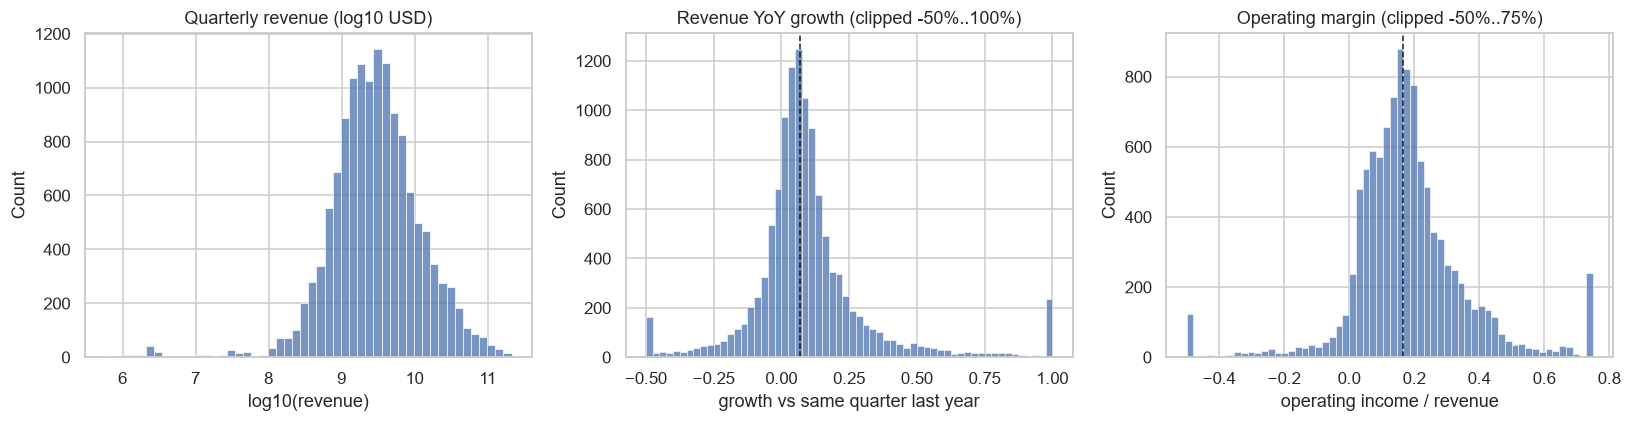

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(np.log10(rev.dropna()), bins=50, ax=ax[0])
ax[0].set(title="Quarterly revenue (log10 USD)", xlabel="log10(revenue)")
sns.histplot(e["revenue_yoy"].clip(-0.5, 1).dropna(), bins=60, ax=ax[1])
ax[1].axvline(e["revenue_yoy"].median(), color="k", ls="--", lw=1)
ax[1].set(title="Revenue YoY growth (clipped -50%..100%)", xlabel="growth vs same quarter last year")
sns.histplot(e["operating_margin"].clip(-0.5, 0.75).dropna(), bins=60, ax=ax[2])
ax[2].axvline(e["operating_margin"].median(), color="k", ls="--", lw=1)
ax[2].set(title="Operating margin (clipped -50%..75%)", xlabel="operating income / revenue")
plt.tight_layout(); plt.show()

### 7.1 Revenue over time (Question 1)

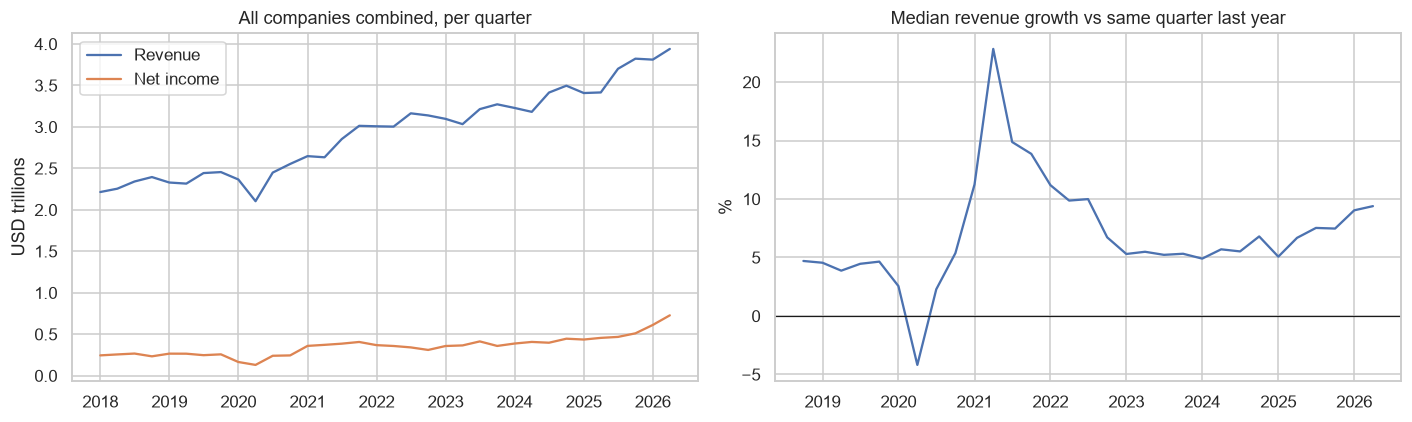

,companies,total_revenue,total_net_income,median_revenue_yoy,median_operating_margin,median_net_margin,median_fcf_margin
quarter,,,,,,,
2018Q1,400,"2,214,595,793,000.00","245,120,488,000.00",NaN,0.15,0.11,0.09
2020Q2,397,"2,104,029,269,000.00","130,138,061,000.00",-0.04,0.14,0.10,0.18
2022Q2,397,"3,003,245,795,000.00","358,403,827,000.00",0.10,0.17,0.13,0.10
2024Q2,397,"3,181,176,286,000.00","407,270,684,000.00",0.06,0.18,0.13,0.13
2026Q2,397,"3,940,034,564,000.00","727,930,531,000.00",0.09,0.19,0.14,0.14


In [ ]:
full = e[(e["quarter"] >= "2018Q1") & (e["quarter"] <= "2026Q2")]   # first and last quarters are incomplete
ts = full.groupby("quarter").agg(companies=("cik", "nunique"),
                                 total_revenue=("revenue", "sum"),
                                 total_net_income=("net_income", "sum"),
                                 median_revenue_yoy=("revenue_yoy", "median"),
                                 median_operating_margin=("operating_margin", "median"),
                                 median_net_margin=("net_margin", "median"),
                                 median_fcf_margin=("fcf_margin", "median"))
x = ts.index.to_timestamp()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(x, ts["total_revenue"] / 1e12, label="Revenue")
ax[0].plot(x, ts["total_net_income"] / 1e12, label="Net income")
ax[0].set(title="All companies combined, per quarter", ylabel="USD trillions"); ax[0].legend()
ax[1].plot(x, ts["median_revenue_yoy"] * 100)
ax[1].axhline(0, color="k", lw=.8)
ax[1].set(title="Median revenue growth vs same quarter last year", ylabel="%")
plt.tight_layout(); plt.show()
ts.loc[["2018Q1", "2020Q2", "2022Q2", "2024Q2", "2026Q2"]]

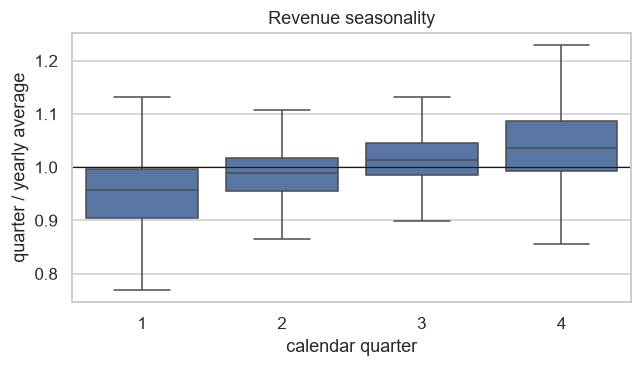

mid_quarter
1   0.96
2   0.99
3   1.01
4   1.04
Name: rel_revenue, dtype: float64

In [ ]:
# Seasonality: each quarter's revenue relative to that company's average quarter in the same year
yr = full[full["mid_year"].between(2018, 2025)].copy()
yr["rel_revenue"] = yr["revenue"] / yr.groupby(["cik", "mid_year"])["revenue"].transform("mean")
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.boxplot(data=yr, x="mid_quarter", y="rel_revenue", showfliers=False, ax=ax)
ax.axhline(1, color="k", lw=.8)
ax.set(title="Revenue seasonality", xlabel="calendar quarter", ylabel="quarter / yearly average")
plt.tight_layout(); plt.show()
yr.groupby("mid_quarter")["rel_revenue"].median().round(3)

In [ ]:
# Does last year's growth say anything about next year's? (simple persistence check)
g = e[["cik", "revenue_yoy"]].copy()
g["revenue_yoy_next4"] = g.groupby("cik")["revenue_yoy"].shift(-4)
g = g.dropna()
g = g[g["revenue_yoy"].between(-0.5, 1) & g["revenue_yoy_next4"].between(-0.5, 1)]
rho = g[["revenue_yoy", "revenue_yoy_next4"]].corr(method="spearman").iloc[0, 1]
print("Spearman correlation, YoY growth now vs four quarters later:", round(rho, 3), f"(n={len(g):,})")

Spearman correlation, YoY growth now vs four quarters later: 0.122 (n=9,779)


### 7.2 Financial stability (Question 2)

In [ ]:
# Strain = trailing four-quarter operating cash flow < 0 AND current ratio < 1
e["ocf_ttm"] = e.groupby("cik")["operating_cash_flow"].transform(lambda s: s.rolling(4, min_periods=4).sum())
e["strain"] = (e["ocf_ttm"] < 0) & (e["current_ratio"] < 1)
has_inputs = e["ocf_ttm"].notna() & e["current_ratio"].notna()
print("rows with both inputs:      ", f"{has_inputs.sum():,} of {len(e):,}")
print("rows in strain:             ", int(e["strain"].sum()), f"({e.loc[has_inputs, 'strain'].mean():.2%} of rows with inputs)")
print("companies ever in strain:   ", e.loc[e["strain"], "ticker"].nunique())
print("current ratio < 1 only:     ", f"{(e.loc[has_inputs, 'current_ratio'] < 1).mean():.1%} of rows")
print("negative TTM OCF only:      ", f"{(e.loc[has_inputs, 'ocf_ttm'] < 0).mean():.1%} of rows")
e.loc[e["strain"]].groupby("ticker").size().sort_values(ascending=False).head(10).rename("quarters in strain").to_frame()

rows with both inputs:       10,426 of 13,966
rows in strain:              48 (0.46% of rows with inputs)
companies ever in strain:    14
current ratio < 1 only:      26.1% of rows
negative TTM OCF only:       2.1% of rows


,quarters in strain
ticker,
CCL,8
RCL,8
TTWO,8
NFLX,5
NCLH,4
PCG,4
ATO,2
DAL,2
ECHO,2


The strain outcome is **rare**, so Question 2 needs care: check how many positive cases remain after the chronological split, or relax the definition (e.g. each condition separately).

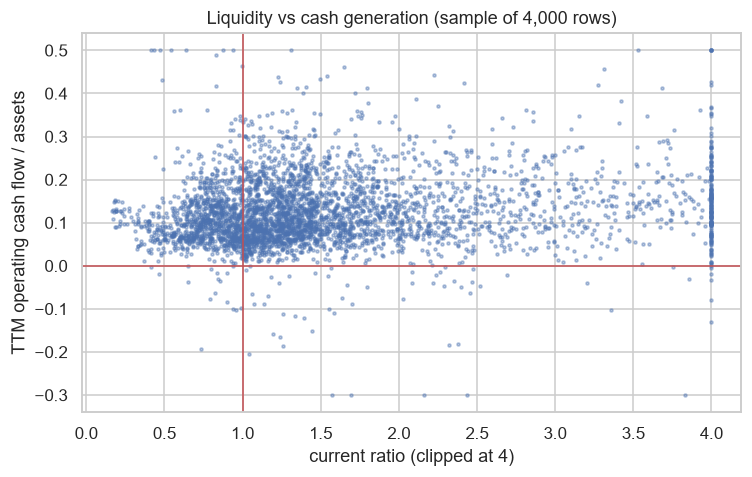

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
s = e[has_inputs].sample(4000, random_state=0)
ax.scatter(s["current_ratio"].clip(0, 4), (s["ocf_ttm"] / s["assets"]).clip(-0.3, 0.5), s=4, alpha=.4)
ax.axvline(1, color="#c44e52", lw=1); ax.axhline(0, color="#c44e52", lw=1)
ax.set(title="Liquidity vs cash generation (sample of 4,000 rows)",
       xlabel="current ratio (clipped at 4)", ylabel="TTM operating cash flow / assets")
plt.tight_layout(); plt.show()

### 7.3 Operating profitability (Question 3)

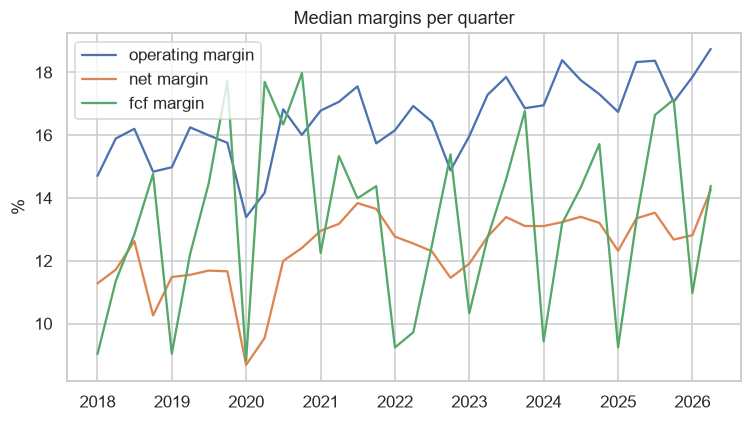

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
for c in ["median_operating_margin", "median_net_margin", "median_fcf_margin"]:
    ax.plot(x, ts[c] * 100, label=c.replace("median_", "").replace("_", " "))
ax.set(title="Median margins per quarter", ylabel="%"); ax.legend()
plt.tight_layout(); plt.show()

In [ ]:
# Baseline for Question 3: margin in the same quarter last year
m = e[["cik", "operating_margin"]].copy()
m["margin_last_year"] = m.groupby("cik")["operating_margin"].shift(4)
m["margin_last_quarter"] = m.groupby("cik")["operating_margin"].shift(1)
m = m.dropna()
m = m[m[["operating_margin", "margin_last_year", "margin_last_quarter"]].abs().lt(1).all(axis=1)]
print(f"rows usable: {len(m):,}")
print("MAE, same quarter last year (pp):", round((m["operating_margin"] - m["margin_last_year"]).abs().mean() * 100, 2))
print("MAE, previous quarter (pp):      ", round((m["operating_margin"] - m["margin_last_quarter"]).abs().mean() * 100, 2))

rows usable: 9,121
MAE, same quarter last year (pp): 6.02
MAE, previous quarter (pp):       5.5


# The most important indicators, in order:

Operating margin (+0.80 with the margin one year ahead)
Previous quarter's margin (+0.73)
Margin in the same quarter last year (+0.73)
Net margin (+0.72)
Operating cash flow margin (+0.56)
Free cash flow margin (+0.50)
Gross margin (+0.46)
ROA (+0.43)
R&D intensity (+0.32 with revenue growth)

# BY addibg more features it will be possible to make better predictions




